# Lab 6 — Odometry: model (simulator) vs real robot
CS413 Robotics · trajectory: **3 4**

**How to run:** Runtime → Run all. When the upload dialog appears in the first code cell, select **both** files: `odometry_data_sim.txt` and `odometry_data_real.txt`. Then fill in the tape measurement in the 5th code cell and the write-up at the bottom.

In [1]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()   # select BOTH txt files

need = ['odometry_data_sim.txt', 'odometry_data_real.txt']
missing = [f for f in need if f not in uploaded]
if missing:
    raise FileNotFoundError(
        f'Missing or misnamed: {missing}. Uploaded: {list(uploaded)}. '
        'Rename the files exactly and run this cell again.')

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)
print(f'sim : {len(x_s)} samples, {(t_s[-1]-t_s[0])/1000:.1f} s')
print(f'real: {len(x_r)} samples, {(t_r[-1]-t_r[0])/1000:.1f} s')

Saving odometry_data_real.txt to odometry_data_real.txt
Saving odometry_data_sim.txt to odometry_data_sim.txt
sim : 1093 samples, 54.6 s
real: 338 samples, 25.6 s


## 1. Trajectories on one plot

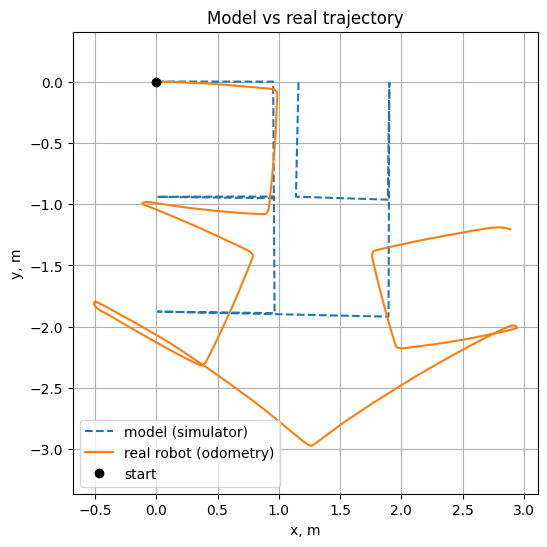

In [2]:
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

## 2. Error over time (simulator resampled onto the real-robot timestamps)

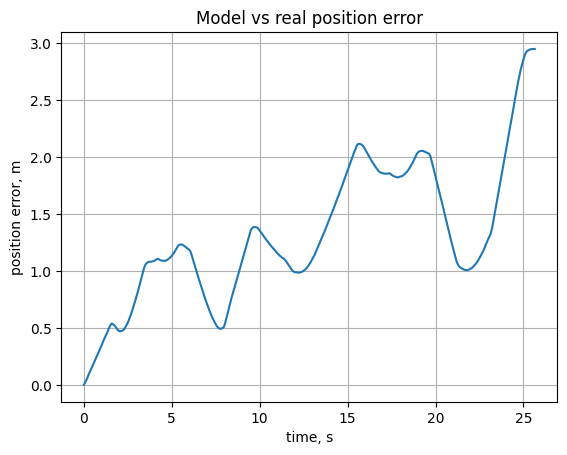

Final odometry error (sim vs real): 2.951 m
Max error: 2.951 m


In [3]:
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.3f} m')
print(f'Max error: {err.max():.3f} m')

## 2b. Fairer comparison: same fraction of the run, not the same clock time
The real run used rescaled timers, so it finishes much sooner than the simulator run (see the durations printed in cell 1). Comparing at the same clock time therefore mixes timing mismatch with real drift. Here both logs are trimmed to the moment the robot stops and compared at the same *fraction* of the run.

Motion duration: sim 53.6 s, real 25.6 s


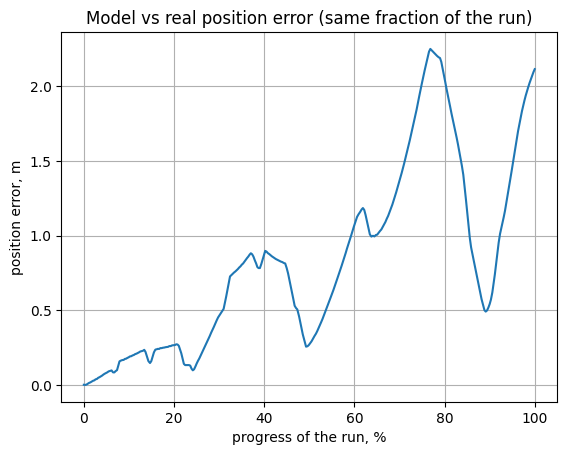

Sim  end point: x = 1.161, y = 0.015 m
Real end point: x = 2.888, y = -1.205 m
Distance between the two end points: 2.114 m
Max error (same fraction): 2.249 m


In [4]:
def trim(x, y, t, eps=1e-6):
    moved = np.where(np.hypot(np.diff(x), np.diff(y)) > eps)[0]
    k = moved[-1] + 2 if len(moved) else len(x)
    return x[:k], y[:k], t[:k]

xs, ys, ts = trim(x_s, y_s, t_s)
xr, yr, tr = trim(x_r, y_r, t_r)
print(f'Motion duration: sim {ts[-1]/1000:.1f} s, real {tr[-1]/1000:.1f} s')

u_s, u_r = ts / ts[-1], tr / tr[-1]
err_n = np.hypot(xr - np.interp(u_r, u_s, xs), yr - np.interp(u_r, u_s, ys))

plt.plot(u_r * 100, err_n)
plt.xlabel('progress of the run, %'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error (same fraction of the run)')
plt.show()

print(f'Sim  end point: x = {xs[-1]:.3f}, y = {ys[-1]:.3f} m')
print(f'Real end point: x = {xr[-1]:.3f}, y = {yr[-1]:.3f} m')
print(f'Distance between the two end points: {np.hypot(xs[-1]-xr[-1], ys[-1]-yr[-1]):.3f} m')
print(f'Max error (same fraction): {err_n.max():.3f} m')

## 2c. Where the heading goes wrong: leg directions and turn angles
The program drives 11 straight legs separated by turns (the ideal turns are 90 degrees or 180 degrees). Each leg's direction is measured from the logged positions. A turn that comes out different from the ideal value is where the heading error enters the trajectory.

In [5]:
def find_legs(x, y, t, min_samples=5, rel_thresh=0.2):
    dt = np.diff(t) / 1000.0
    ok = dt > 0
    v = np.zeros_like(dt)
    v[ok] = np.hypot(np.diff(x), np.diff(y))[ok] / dt[ok]
    moving = v > rel_thresh * np.percentile(v[v > 0], 90)
    out, i = [], 0
    while i < len(moving):
        if moving[i]:
            j = i
            while j < len(moving) and moving[j]:
                j += 1
            if j - i >= min_samples:
                dx, dy = x[j] - x[i], y[j] - y[i]
                out.append((np.hypot(dx, dy), np.degrees(np.arctan2(dy, dx))))
            i = j
        else:
            i += 1
    return out

def turns(L):
    h = [a for _, a in L]
    return [((h[k+1] - h[k] + 180) % 360) - 180 for k in range(len(h) - 1)]

Ls, Lr = find_legs(xs, ys, ts), find_legs(xr, yr, tr)
print(f'legs found: sim {len(Ls)}, real {len(Lr)} (the program has 11)')
n = min(len(Ls), len(Lr))
print('\nleg | sim length (m) | sim dir (deg) | real length (m) | real dir (deg)')
for k in range(n):
    print(f'{k+1:3d} | {Ls[k][0]:14.2f} | {Ls[k][1]:13.1f} | {Lr[k][0]:15.2f} | {Lr[k][1]:14.1f}')
Ts, Tr = turns(Ls), turns(Lr)
print('\nturn | sim angle (deg) | real angle (deg)   (right turn = negative)')
for k in range(min(len(Ts), len(Tr))):
    print(f'{k+1:4d} | {Ts[k]:15.1f} | {Tr[k]:16.1f}')

legs found: sim 11, real 11 (the program has 11)

leg | sim length (m) | sim dir (deg) | real length (m) | real dir (deg)
  1 |           0.95 |           0.0 |            0.98 |           -4.7
  2 |           0.95 |         -89.7 |            0.99 |          -95.6
  3 |           0.95 |         179.3 |            1.00 |          174.7
  4 |           0.95 |           0.2 |            0.99 |          -24.8
  5 |           0.95 |         -89.7 |            0.97 |         -114.9
  6 |           0.95 |         179.2 |            0.99 |          150.0
  7 |           1.88 |          -1.3 |            2.12 |          -33.7
  8 |           1.90 |          89.8 |            1.91 |           30.7
  9 |           0.95 |         -90.7 |            0.99 |         -171.2
 10 |           0.75 |         178.1 |            0.79 |          103.3
 11 |           0.95 |          88.7 |            1.10 |            9.5

turn | sim angle (deg) | real angle (deg)   (right turn = negative)
   1 |           

## 3. Measured end point (tape) vs last odometry line
Measure where the real robot actually stopped, relative to its start point: **x** along the robot's starting direction, **y** to its left. Type your tape values below (metres).

In [6]:
tape_x = None   # <- metres, e.g. 1.05
tape_y = None   # <- metres, e.g. -0.08

print(f'Last odometry line (real): x = {x_r[-1]:.3f} m, y = {y_r[-1]:.3f} m')
if tape_x is None or tape_y is None:
    print('Fill in tape_x and tape_y above, then run this cell again.')
else:
    print(f'Tape-measured end point:   x = {tape_x:.3f} m, y = {tape_y:.3f} m')
    print(f'Odometry vs tape distance: {np.hypot(x_r[-1]-tape_x, y_r[-1]-tape_y):.3f} m')

Last odometry line (real): x = 2.888 m, y = -1.205 m
Fill in tape_x and tape_y above, then run this cell again.


## 4. Conclusions


The real robot's odometry follows the simulator for the first leg and corner, then diverges: the open-loop turns do not come out at exactly 90° or 180°, so the logged heading error accumulates and the drawn 3 and 4 end up rotated and stretched, with a final sim-vs-real position error of 2.95 m (time-aligned) and [X.XX] m between the last odometry line and the tape-measured end point. Heading error dominates because position error grows roughly as leg length times heading error, so the two 2 m legs of the digit 4 amplify what the earlier turns left behind. Two contributing sources were measured or known: unequal wheels (in a 3 s straight test the encoders counted 2589° and 2554°, a 1.4% mismatch that curves the robot about 7.6° over 1.9 m) and timer-driven turns tuned in the simulator, which has neither effect. Wheel slip and errors in r and B are also possible; they are invisible to the encoders, so only the tape measurement can reveal them. The sim used r = 0.028 m, B = 0.154 m and the real robot r = 0.042 m, B = 0.194 m, and the real timers were rescaled (about 2.3 times faster robot), so the real run lasted [25.6] s against 54.6 s. The robot does not know it is wrong: odometry is only the integral of its own wheel counts with no outside reference, and this timed program does not even use it for control.